In [1]:
import os
import sys
import pandas as pd
import numpy as np
import muon as mu
import scanpy as sc
import anndata as ad
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

import pickle

from scipy.cluster.hierarchy import fcluster
from scipy.cluster.hierarchy import dendrogram, linkage
from matplotlib.patches import Rectangle
import matplotlib.patches as mpatches

import re
import seaborn as sns

In [2]:
work_dir = '/lustre/scratch125/casm/teams/team215/users/od5/projects/celltherapy/ipsc/multiome/scenicplus/tf_pilot/batch1/ipsc/'

In [3]:
output_dir = work_dir + 'scenicplus_full/eRegulon_AUC_dotplot/'
os.makedirs(output_dir, exist_ok=True)

In [4]:
grouping_var = 'perturbation'

In [5]:
## Read AUC object
gene_auc = pd.read_csv(work_dir + 'scenicplus_full/eRegulon_AUC_genes.csv', index_col=0)

In [6]:
gene_auc

,ARID3A_+_+_(14g),BACH2_+_+_(164g),BCL11A_-_+_(13g),BPTF_-_+_(49g),CEBPZ_+_+_(347g),CEBPZ_-_+_(71g),DRAP1_+_+_(507g),E2F1_-_+_(19g),E2F7_+_+_(32g),EGR1_-_+_(19g),...,TEAD1_+_+_(98g),THRB_+_+_(49g),THRB_-_+_(27g),ZBTB14_-_+_(13g),ZBTB16_+_+_(24g),ZBTB16_-_+_(32g),ZEB1_+_+_(178g),ZNF518A_-_+_(52g),ZSCAN10_+_+_(242g),ZSCAN10_-_+_(347g)
Cell,,,,,,,,,,,,,,,,,,,,,
CEBPD-SEACell-0,0.0,0.000000,0.0,0.000000,0.003774,0.010731,0.004720,0.0,0.0,0.0,...,0.000486,0.0,0.048501,0.0,0.0,0.103423,0.000000,0.0,0.017119,0.000000
CEBPD-SEACell-1,0.0,0.000000,0.0,0.000000,0.012385,0.008719,0.011905,0.0,0.0,0.0,...,0.000000,0.0,0.060406,0.0,0.0,0.098586,0.000602,0.0,0.014709,0.000000
CEBPD-SEACell-10,0.0,0.000000,0.0,0.000000,0.012179,0.010060,0.010989,0.0,0.0,0.0,...,0.000000,0.0,0.053351,0.0,0.0,0.094866,0.000000,0.0,0.013233,0.000000
CEBPD-SEACell-11,0.0,0.001597,0.0,0.005345,0.010052,0.003689,0.009604,0.0,0.0,0.0,...,0.005224,0.0,0.034832,0.0,0.0,0.090402,0.001471,0.0,0.010675,0.001475
CEBPD-SEACell-12,0.0,0.000000,0.0,0.000000,0.002058,0.010563,0.002606,0.0,0.0,0.0,...,0.000000,0.0,0.052028,0.0,0.0,0.093006,0.001873,0.0,0.017119,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TCF7-SEACell-47,0.0,0.001597,0.0,0.000000,0.016879,0.000000,0.013783,0.0,0.0,0.0,...,0.000000,0.0,0.063492,0.0,0.0,0.097470,0.000000,0.0,0.011659,0.000000
TCF7-SEACell-48,0.0,0.000000,0.0,0.000000,0.026829,0.000000,0.021908,0.0,0.0,0.0,...,0.000000,0.0,0.055556,0.0,0.0,0.089286,0.000000,0.0,0.007133,0.000000
TCF7-SEACell-5,0.0,0.003412,0.0,0.000000,0.019487,0.000000,0.017352,0.0,0.0,0.0,...,0.004130,0.0,0.057319,0.0,0.0,0.097842,0.000000,0.0,0.006739,0.001166


In [7]:
## Read mdata object
mdata = mu.read_h5mu('/lustre/scratch125/casm/teams/team215/users/od5/projects/celltherapy/ipsc/multiome/seacells_gex/tf_pilot/batch1/ipsc/seacells_annot_min10cells.h5mu')

In [8]:
mdata['rna'].X.sum(axis=1)

matrix([[10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [1

In [9]:
## Log1p normalise
sc.pp.log1p(mdata['rna'])

In [10]:
## Identify TFs
tfs = pd.Series(gene_auc.columns).str.split('_', expand=True)[0].unique()

In [11]:
## Summarise AUC per grouping variable (e.g., cell type)
mean_auc = []
## Get mean expression - expects scaled and log1p object
mean_tf_exp = []
for ct in mdata.obs[grouping_var].unique():
    ## Identify cells
    cells = mdata.obs_names[mdata.obs[grouping_var]==ct]
    ## Mean AUC
    mean_auc.append(np.ravel(gene_auc.loc[cells, :].mean(axis=0)))
    ## Mean AUC
    mean_tf_exp.append(np.ravel(mdata['rna'][cells, tfs].X.mean(axis=0)))

auc_pseudo = pd.DataFrame(np.vstack(mean_auc), index=mdata.obs[grouping_var].unique().tolist(), columns=gene_auc.columns)
tf_exp_pseudo = pd.DataFrame(np.vstack(mean_tf_exp), index=mdata.obs[grouping_var].unique().tolist(), columns=tfs.tolist())

In [12]:
auc_pseudo.max(axis=0).describe()

count    65.000000
mean      0.012325
std       0.017668
min       0.000000
25%       0.000000
50%       0.008799
75%       0.015769
max       0.088049
dtype: float64

In [13]:
## Keeping TFs with AUC > 0
auc_pseudo = auc_pseudo.loc[:, auc_pseudo.max(axis=0) > 0]

In [14]:
auc_pseudo

,BACH2_+_+_(164g),BCL11A_-_+_(13g),BPTF_-_+_(49g),CEBPZ_+_+_(347g),CEBPZ_-_+_(71g),DRAP1_+_+_(507g),ELK4_+_+_(29g),EOMES_+_+_(42g),EOMES_-_+_(13g),FOSL1_+_+_(62g),...,SOX4_-_+_(131g),SP5_+_+_(68g),TEAD1_+_+_(98g),THRB_+_+_(49g),THRB_-_+_(27g),ZBTB16_+_+_(24g),ZBTB16_-_+_(32g),ZEB1_+_+_(178g),ZSCAN10_+_+_(242g),ZSCAN10_-_+_(347g)
TCF7,0.000642,0.000000,0.001104,0.024836,0.001456,0.020836,0.000140,0.003350,0.000000,0.000480,...,0.005500,0.001997,0.001295,0.000436,0.053461,0.000203,0.077880,0.000777,0.008898,0.000412
CEBPD,0.000069,0.000000,0.000232,0.020895,0.006408,0.017792,0.000518,0.005817,0.008799,0.000000,...,0.007724,0.003098,0.000248,0.000000,0.049459,0.000000,0.079484,0.000846,0.009969,0.000064
RUNX2,0.012097,0.004186,0.013172,0.013804,0.009725,0.014637,0.000000,0.003847,0.008700,0.022973,...,0.005297,0.002376,0.011775,0.017094,0.010456,0.011692,0.016714,0.010070,0.002818,0.007479
FOXO3,0.000265,0.000000,0.000317,0.020379,0.001217,0.017200,0.000000,0.007739,0.000000,0.000000,...,0.006701,0.004491,0.000697,0.000000,0.055958,0.000000,0.086115,0.000230,0.011024,0.000134
EBF1,0.001063,0.000000,0.003228,0.011152,0.007042,0.010249,0.000000,0.027656,0.000000,0.000000,...,0.005303,0.015769,0.000816,0.000000,0.036691,0.000000,0.056707,0.003129,0.007980,0.000233
TBX21,0.000704,0.000780,0.001764,0.017316,0.001919,0.015562,0.000000,0.004000,0.000000,0.000050,...,0.004837,0.002205,0.001881,0.000000,0.038621,0.000000,0.075163,0.001090,0.008729,0.000579
HOPX,0.000374,0.000954,0.000704,0.023768,0.000950,0.020138,0.000000,0.005132,0.000630,0.000036,...,0.005691,0.003133,0.000696,0.000000,0.055657,0.000000,0.082101,0.000674,0.010581,0.000222
Control,0.000917,0.000000,0.001398,0.021255,0.001341,0.018184,0.000000,0.004943,0.001184,0.001368,...,0.006561,0.003062,0.001387,0.001102,0.053179,0.000665,0.081237,0.001020,0.010751,0.000527
PRDM1,0.000133,0.017247,0.000445,0.014163,0.000587,0.012983,0.000000,0.014243,0.000534,0.000000,...,0.004521,0.007134,0.001417,0.000000,0.038029,0.000000,0.054036,0.006543,0.009999,0.000129


In [15]:
tf_exp_pseudo

,ARID3A,BACH2,BCL11A,BPTF,CEBPZ,DRAP1,E2F1,E2F7,EGR1,ELK4,...,SP5,TBX15,TCF7L1,TEAD1,THRB,ZBTB14,ZBTB16,ZEB1,ZNF518A,ZSCAN10
TCF7,0.572306,0.597088,1.127309,1.631977,1.289974,0.659353,0.321479,0.551274,0.301727,0.478339,...,0.053799,0.015756,1.463539,1.365362,0.358759,0.151795,0.044165,0.179714,0.972264,0.916904
CEBPD,0.739714,0.660001,1.116575,1.647504,1.272112,0.641648,0.326988,0.527352,0.309551,0.439665,...,0.093485,0.027050,1.445052,1.338784,0.369342,0.134044,0.029956,0.186687,1.036304,0.878715
RUNX2,0.841058,1.266096,1.149460,1.467770,1.046157,0.604976,0.310803,0.535219,0.101222,0.441037,...,0.213039,0.116803,1.327214,1.613448,0.865781,0.109302,0.337982,1.016379,1.056307,0.288263
FOXO3,0.517160,0.697288,1.098138,1.660763,1.327424,0.598855,0.334758,0.604733,0.403422,0.555946,...,0.053612,0.017824,1.490997,1.351645,0.205741,0.124319,0.018969,0.132665,1.019831,0.917495
EBF1,0.680620,0.851233,1.185657,1.643882,1.014080,0.505823,0.332983,0.626309,0.217857,0.403206,...,0.543064,0.128262,1.501298,1.320154,0.169272,0.083111,0.026345,0.660353,1.101608,0.693250
TBX21,0.548759,0.680268,1.160505,1.618332,1.263661,0.660804,0.336370,0.532090,0.391895,0.416234,...,0.133675,0.029962,1.570558,1.376826,0.221230,0.137648,0.045518,0.260919,1.010728,0.787595
HOPX,0.564054,0.589863,1.058377,1.643627,1.321547,0.624832,0.328579,0.582547,0.334525,0.444248,...,0.088288,0.017204,1.461031,1.339313,0.368097,0.152136,0.042972,0.147542,0.958988,0.930550
Control,0.523232,0.595269,1.113379,1.635648,1.294266,0.643738,0.340247,0.581399,0.298059,0.460511,...,0.051496,0.020682,1.501499,1.349031,0.387973,0.135182,0.041277,0.180114,1.009346,0.914794
PRDM1,0.730000,0.528311,0.778595,1.640365,1.247363,0.642233,0.306155,0.557209,0.314071,0.463175,...,0.307704,0.012733,1.097069,1.502496,0.372740,0.143579,0.058134,0.427051,1.003854,0.753219


In [16]:
## Max scale AUC and exp across cell types
auc_pseudo = auc_pseudo / auc_pseudo.max(axis=0)
tf_exp_pseudo = tf_exp_pseudo / tf_exp_pseudo.max(axis=0)

In [17]:
## Summarise into a single dataframe
auc_pseudo_long = auc_pseudo.melt(value_name='AUC', var_name='Regulon', ignore_index=False)
auc_pseudo_long['group'] = auc_pseudo_long.index.tolist()
auc_pseudo_long = auc_pseudo_long.reset_index(drop=True)
auc_pseudo_long['TF'] = auc_pseudo_long['Regulon'].str.split('_', expand=True)[0]
auc_pseudo_long['TF_target_count'] = auc_pseudo_long['Regulon'].str.split('_', expand=True)[3].str.replace('(', '').str.replace(')', '').str.replace('g', '').astype(int)
auc_pseudo_long['class'] = auc_pseudo_long['Regulon'].apply(lambda x: 'activator' if '+_+' in x else 'repressor')


tf_exp_long = tf_exp_pseudo.melt(value_name='Exp', var_name='TF', ignore_index=False)
tf_exp_long['group'] = tf_exp_long.index.tolist()
tf_exp_long = tf_exp_long.reset_index(drop=True)

In [18]:
merged_df = pd.merge(auc_pseudo_long, tf_exp_long, on=['TF', 'group'], how='left')

In [19]:
merged_df = merged_df.sort_values(['group', 'AUC'], ascending=False)

In [20]:
merged_df.head()

,Regulon,AUC,group,TF,TF_target_count,class,Exp
27,CEBPZ_+_+_(347g),1.0,TCF7,CEBPZ,347,activator,0.971787
45,DRAP1_+_+_(507g),1.0,TCF7,DRAP1,507,activator,0.997804
171,KLF7_-_+_(166g),1.0,TCF7,KLF7,166,repressor,0.646336
207,MEF2A_-_+_(86g),1.0,TCF7,MEF2A,86,repressor,0.855026
252,POU5F1_+_+_(616g),1.0,TCF7,POU5F1,616,activator,0.981872


In [21]:
merged_df['group'].unique()

array(['TCF7', 'TBX21', 'RUNX2', 'PRDM1', 'HOPX', 'FOXO3', 'EBF1',
       'Control', 'CEBPD'], dtype=object)

In [22]:
## Focusing on activators with at least 10 targets
merged_df_filt = merged_df[(merged_df['class']=='activator') & (merged_df['TF_target_count'] >=10)]
auc_pseudo_filt = auc_pseudo.loc[:,merged_df_filt['Regulon'].unique()]

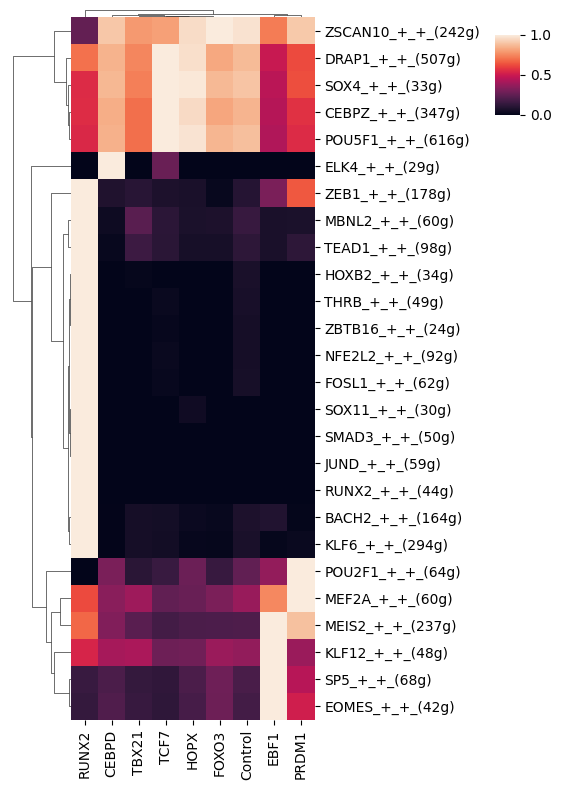

In [23]:
## Cluster based on AUC
g = sns.clustermap(
    auc_pseudo_filt.transpose(),
    xticklabels=True,
    yticklabels=True,
    figsize=(5,8),
    dendrogram_ratio=(0.2, 0.01), 
    cbar_pos=(1, 0.85, 0.05,0.1), 
    method='average')

In [24]:
## Extract clustering:
tf_dendrogram = g.dendrogram_row.linkage
tf_cluster_ids = fcluster(tf_dendrogram , 20, criterion='maxclust')
# Map cluster IDs back to column names
tf_cluster_map = pd.DataFrame({'Regulon':auc_pseudo_filt.columns, 'TF_cluster': tf_cluster_ids})

group_dendrogram_indices = g.dendrogram_col.reordered_ind

In [25]:
group_ordering = auc_pseudo_filt.index[group_dendrogram_indices]

In [26]:
merged_df_filt = pd.merge(merged_df_filt, tf_cluster_map, on ='Regulon', how='left')

In [27]:
merged_df_filt['group'] = pd.Categorical(merged_df_filt['group'], categories=group_ordering, ordered=True)

In [28]:
merged_df_filt = merged_df_filt.sort_values(['TF_cluster', 'TF','group'])

In [29]:
merged_df_filt.head(20)

,Regulon,AUC,group,TF,TF_target_count,class,Exp,TF_cluster
69,CEBPZ_+_+_(347g),0.555812,RUNX2,CEBPZ,347,activator,0.788111,1
213,CEBPZ_+_+_(347g),0.841326,CEBPD,CEBPZ,347,activator,0.958331,1
30,CEBPZ_+_+_(347g),0.697243,TBX21,CEBPZ,347,activator,0.951964,1
0,CEBPZ_+_+_(347g),1.000000,TCF7,CEBPZ,347,activator,0.971787,1
108,CEBPZ_+_+_(347g),0.957015,HOPX,CEBPZ,347,activator,0.995572,1
134,CEBPZ_+_+_(347g),0.820545,FOXO3,CEBPZ,347,activator,1.000000,1
186,CEBPZ_+_+_(347g),0.855821,Control,CEBPZ,347,activator,0.975021,1
164,CEBPZ_+_+_(347g),0.449050,EBF1,CEBPZ,347,activator,0.763946,1
85,CEBPZ_+_+_(347g),0.570283,PRDM1,CEBPZ,347,activator,0.939687,1
71,POU5F1_+_+_(616g),0.546442,RUNX2,POU5F1,616,activator,0.581774,2


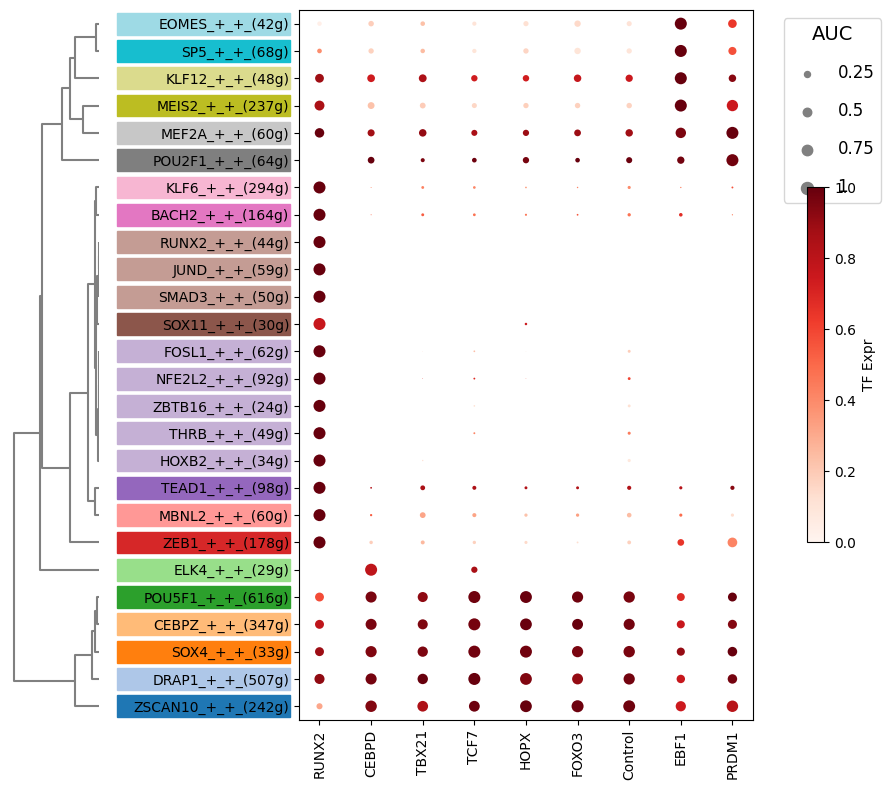

In [30]:
# Create a figure to hold both the dendrogram and the scatter plot
fig, (ax_dendro, ax_scatter) = plt.subplots(1, 2, figsize=(9, 8), gridspec_kw={'width_ratios': [1, 6]})

# Create dendrogram
dendro = dendrogram(tf_dendrogram, orientation='left', ax=ax_dendro, above_threshold_color='gray', color_threshold=0)
ax_dendro.set_xticks([])
ax_dendro.set_yticks([])

for spine in ax_dendro.spines.values():
    spine.set_visible(False)
ax_dendro.set_axis_off()

# Reorder data according to the dendrogram
dendro_order = dendro['leaves']

# Make sure scatterplot order will be the same
merged_df_filt['Regulon'] = pd.Categorical(merged_df_filt['Regulon'], categories=auc_pseudo_filt.columns[dendro_order], ordered=True)
merged_df_filt = merged_df_filt.reset_index(drop=True)
merged_df_filt['dendro_order'] = merged_df_filt['Regulon'].cat.codes
merged_df_filt.sort_values('dendro_order', inplace=True)

size_factor = 75
# Scatterplot
sns.scatterplot(
    data=merged_df_filt,
    x='group',
    y='Regulon',
    size='AUC',
    hue='Exp',
    palette='Reds',
    ax=ax_scatter,
    sizes=(merged_df_filt['AUC'].min()*size_factor, merged_df_filt['AUC'].max()*size_factor),
    legend=False  # We'll add a custom legend later
)
ax_scatter.set_ylim(-0.5, (len(merged_df_filt['Regulon'].unique()) - 0.5))

# Unique clusters for color coding
clusters = merged_df_filt['TF_cluster'].unique()
colors = plt.get_cmap('tab20').colors
cluster_color = dict(zip(clusters, colors))

# Adding rectangles
for i, regulon in enumerate(merged_df_filt['Regulon'].unique()):
    cluster = merged_df_filt[merged_df_filt['Regulon'] == regulon]['TF_cluster'].iloc[0]
    color = cluster_color[cluster]
    rect = Rectangle((-0.4, i-0.4), 0.38, 0.8, color=color, transform=ax_scatter.get_yaxis_transform(), clip_on=False)
    ax_scatter.add_patch(rect)

# Create a legend for the sizes
size_values = [0.25, 0.5, 0.75, 1]
size_handles = [plt.scatter([], [], s=size*size_factor, color='gray', label=str(size)) for size in size_values]

## And one for the color
norm = Normalize(vmin=merged_df_filt['Exp'].min(), vmax=merged_df_filt['Exp'].max())
sm = ScalarMappable(cmap="Reds", norm=norm)
sm.set_array([])
colorbar = plt.colorbar(sm, ax=ax_scatter, fraction=0.05, pad=0.1, shrink=0.5)
colorbar.set_label('TF Expr')

legend = ax_scatter.legend(handles=size_handles, title="AUC", labelspacing=1.2,
                           loc='upper left', bbox_to_anchor=(1.05, 1),title_fontsize = 14, fontsize=12)

plt.xlabel('')
plt.ylabel('')
plt.xticks(rotation=90)

plt.tight_layout()

plt.savefig(output_dir + 'GRN_activators_regulons.pdf')

plt.show()


In [31]:
merged_df_filt

,Regulon,AUC,group,TF,TF_target_count,class,Exp,TF_cluster,dendro_order
44,ZSCAN10_+_+_(242g),0.907014,PRDM1,ZSCAN10,242,activator,0.809434,5,0
43,ZSCAN10_+_+_(242g),0.723890,EBF1,ZSCAN10,242,activator,0.744990,5,0
42,ZSCAN10_+_+_(242g),0.975231,Control,ZSCAN10,242,activator,0.983068,5,0
41,ZSCAN10_+_+_(242g),1.000000,FOXO3,ZSCAN10,242,activator,0.985972,5,0
40,ZSCAN10_+_+_(242g),0.959821,HOPX,ZSCAN10,242,activator,1.000000,5,0
...,...,...,...,...,...,...,...,...,...
203,EOMES_+_+_(42g),0.279840,FOXO3,EOMES,42,activator,0.145026,17,25
202,EOMES_+_+_(42g),0.185548,HOPX,EOMES,42,activator,0.122364,17,25
201,EOMES_+_+_(42g),0.121123,TCF7,EOMES,42,activator,0.103478,17,25
200,EOMES_+_+_(42g),0.144623,TBX21,EOMES,42,activator,0.233877,17,25


In [32]:
merged_df_filt['TF_cluster'].unique()

array([ 5,  4,  3,  1,  2, 20, 13,  6,  7,  8, 10,  9, 11, 12, 19, 14, 15,
       18, 16, 17], dtype=int32)

In [33]:
## Save everything we need to reproduce this figure into a dictionary and pickling:
save_dir = {
    'merged_df_filt': merged_df_filt,
    'tf_dendrogram': tf_dendrogram
}

In [34]:
with open((output_dir + 'GRN_activators_AUC_dat.pkl'), 'wb') as f:
    pickle.dump(save_dir, f)

In [35]:
with open((output_dir + 'GRN_activators_AUC_dat.pkl'), 'rb') as f:
    save_dir = pickle.load(f)

In [36]:
save_dir['merged_df_filt'].to_csv(output_dir + 'GRN_activators_AUC.csv')

In [37]:
tfs = ['POU5F1', 'SOX4', 'ZSCAN10', 'CEBPZ', 'DRAP1',
       'ELK4',
       'MEF2A', 'POU2F1',
        'EOMES', 'KLF12', 'SP5', 'MEIS2',
      'RUNX2', 'BACH2', 'FOSL1', 'JUND', 'NFE2L2', 'KLF6', 'HOXB2', 'SMAD3', 'SOX11', 'TEAD1', 'THRB', 'ZBTB16', 'ZEB1']

In [38]:
groups = ['Control', 'FOXO3', 'HOPX',  'TCF7', 'CEBPD', 'TBX21', 'PRDM1', 'EBF1', 'RUNX2']

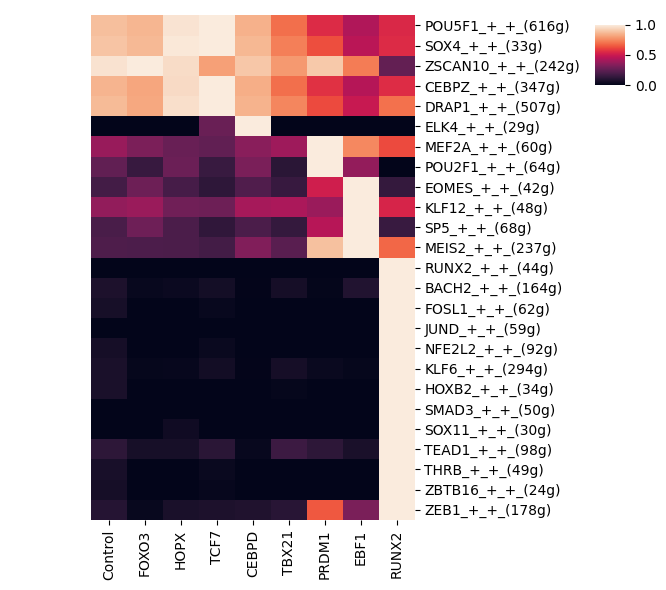

In [39]:
# Keep only selected TFs, selected groups, and positive regulons
merged_df_filt = merged_df[
    merged_df['TF'].isin(tfs)
    & merged_df['group'].isin(groups)
    & merged_df['Regulon'].str.contains(r'\+_\+', regex=True, na=False)
].copy()

# Order TFs by your TF list
merged_df_filt['TF'] = pd.Categorical(
    merged_df_filt['TF'],
    categories=tfs,
    ordered=True
)

# One row per regulon for column ordering
regulon_order_df = (
    merged_df_filt[['Regulon', 'TF', 'TF_target_count']]
    .drop_duplicates()
    .sort_values(['TF', 'TF_target_count', 'Regulon'], ascending=[True, False, True])
)

regulon_order = regulon_order_df['Regulon'].tolist()

# Matrix with rows ordered as groups
mat = auc_pseudo.loc[groups, regulon_order]

# Plot: rows stay in group order because row_cluster=False
g = sns.clustermap(
    mat.transpose(),
    xticklabels=True,
    yticklabels=True,
    figsize=(6, 6),
    col_cluster=False,
    row_cluster=False,
    dendrogram_ratio=(0.2, 0.01),
    cbar_pos=(1, 0.85, 0.05, 0.1),
    method='average'
)

In [40]:
import project_style_py as scp
scp.load_project_palettes('/lustre/scratch124/humgen/projects_v2/cardinal_analysis/analysis/od5/annotation/freeze3_stats/freeze3_palettes.yaml'
)
scp.load_project_themes(
    '/lustre/scratch124/humgen/projects_v2/cardinal_analysis/analysis/od5/annotation/freeze3_stats/freeze3_themes_py.yaml'
)

import matplotlib as mpl

mpl.rcParams["font.family"] = "sans-serif"
mpl.rcParams["font.sans-serif"] = ["Helvetica"]
mpl.rcParams["pdf.fonttype"] = 42   # keeps text editable in Illustrator
mpl.rcParams["ps.fonttype"] = 42

Successfully loaded palettes from: /software/conda/users/od5/bin2cell/lib/python3.8/site-packages/project_style_py/resources/palettes.yaml
Successfully loaded themes from: /software/conda/users/od5/bin2cell/lib/python3.8/site-packages/project_style_py/resources/themes.yaml
Successfully loaded palettes from: /lustre/scratch124/humgen/projects_v2/cardinal_analysis/analysis/od5/annotation/freeze3_stats/freeze3_palettes.yaml
Successfully loaded themes from: /lustre/scratch124/humgen/projects_v2/cardinal_analysis/analysis/od5/annotation/freeze3_stats/freeze3_themes_py.yaml
Loading fonts for theme: default
Font saved to temporary file: /tmp/tmpln8rg67b.ttf
Font saved to temporary file: /tmp/tmp72g4ofii.ttf
Font saved to temporary file: /tmp/tmpgy_9vesv.ttf
Font saved to temporary file: /tmp/tmpy7fyh4fh.ttf
Loading fonts for theme: theme_bw
Font saved to temporary file: /tmp/tmpe2axyd5d.ttf
Font saved to temporary file: /tmp/tmpabrystfd.ttf
Font saved to temporary file: /tmp/tmpet9bixo9.ttf
F

In [41]:
tfs_dict = {'Pluripotency':['POU5F1', 'SOX4', 'ZSCAN10', 'CEBPZ', 'DRAP1'],
        'CEBPD':['ELK4'],
       'PRDM1':['MEF2A', 'POU2F1'],
        'EBF1':['EOMES', 'KLF12', 'SP5', 'MEIS2'],
        'RUNX2':['RUNX2', 'BACH2', 'FOSL1', 'JUND', 'NFE2L2', 'KLF6', 'HOXB2', 'SMAD3', 'SOX11', 'TEAD1', 'THRB', 'ZBTB16', 'ZEB1'],
           }
       

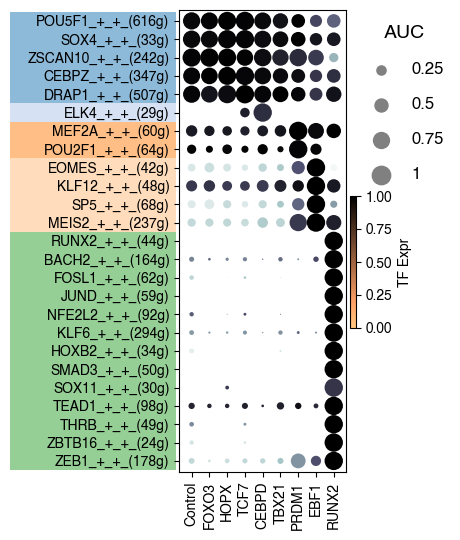

In [62]:
# Keep only selected TFs, selected groups, and positive regulons
merged_df_filt = merged_df[
    merged_df['TF'].isin(tfs)
    & merged_df['group'].isin(groups)
    & merged_df['Regulon'].str.contains(r'\+_\+', regex=True, na=False)
].copy()

# Order TFs by your TF list
merged_df_filt['TF'] = pd.Categorical(
    merged_df_filt['TF'],
    categories=tfs,
    ordered=True
)

# Map TF -> category from tfs_dict
tf_to_group = {
    tf: group_name
    for group_name, tf_list in tfs_dict.items()
    for tf in tf_list
}
merged_df_filt['TF_group'] = merged_df_filt['TF'].map(tf_to_group)

# Build regulon order
regulon_order_df = (
    merged_df_filt[['Regulon', 'TF', 'TF_target_count', 'TF_group']]
    .drop_duplicates()
    .sort_values(['TF', 'TF_target_count', 'Regulon'], ascending=[True, False, True])
)

regulon_order = regulon_order_df['Regulon'].tolist()

# Enforce plotting order
merged_df_filt['Regulon'] = pd.Categorical(
    merged_df_filt['Regulon'],
    categories=regulon_order,
    ordered=True
)
merged_df_filt['group'] = pd.Categorical(
    merged_df_filt['group'],
    categories=groups,
    ordered=True
)

merged_df_filt = merged_df_filt.sort_values(['Regulon', 'group']).reset_index(drop=True)

# Regulon -> TF group mapping in plotted order
regulon_to_group = regulon_order_df.set_index('Regulon')['TF_group'].to_dict()
group_sequence = [regulon_to_group[r] for r in regulon_order]

# Colors
tf_groups = [g for g in tfs_dict.keys() if g in pd.Series(group_sequence).dropna().unique()]
colors = plt.get_cmap('tab20').colors
group_color = dict(zip(tf_groups, colors[:len(tf_groups)]))

# Merge consecutive blocks with same TF group
merged_blocks = []
start = 0
current_group = group_sequence[0]

for i in range(1, len(group_sequence)):
    if group_sequence[i] != current_group:
        merged_blocks.append((start, i - 1, current_group))
        start = i
        current_group = group_sequence[i]

merged_blocks.append((start, len(group_sequence) - 1, current_group))

# Make left panel wider
fig, (ax_blocks, ax_scatter) = plt.subplots(
    1, 2,
    figsize=(4.5, 6),
    gridspec_kw={'width_ratios': [6, 6.5], 'wspace': 0.02}
)

size_factor = 175

# Scatterplot
sns.scatterplot(
    data=merged_df_filt,
    x='group',
    y='Regulon',
    size='AUC',
    hue='Exp',
    palette='bone_r',
    ax=ax_scatter,
    sizes=(
        merged_df_filt['AUC'].min() * size_factor,
        merged_df_filt['AUC'].max() * size_factor
    ),
    legend=False
)

ax_scatter.set_ylim(len(regulon_order) - 0.4, -0.6)
ax_scatter.set_xlim(-0.7, 8.7)


# Left annotation blocks
ax_blocks.set_xlim(0, 1)
ax_blocks.set_ylim(len(regulon_order) - 0.4, -0.6)
ax_blocks.axis('off')

for start, end, group_name in merged_blocks:
    y0 = start - 0.5
    height = end - start + 1
    color = group_color.get(group_name, 'lightgrey')

    rect = Rectangle(
        (0, y0), 1, height,
        facecolor=color,
        edgecolor='none',
        alpha=0.5
    )
    ax_blocks.add_patch(rect)

# Size legend
size_values = [0.25, 0.5, 0.75, 1]
size_handles = [
    plt.scatter([], [], s=size * size_factor, color='gray', label=str(size))
    for size in size_values
]

legend_auc = ax_scatter.legend(
    handles=size_handles,
    title='AUC',
    labelspacing=1.2,
    loc='upper left',
    bbox_to_anchor=(1.02, 1.0),
    title_fontsize=14,
    fontsize=12,
    frameon=False
)

# Colorbar for expression, moved lower
norm = Normalize(vmin=merged_df_filt['Exp'].min(), vmax=merged_df_filt['Exp'].max())
sm = ScalarMappable(cmap='copper_r', norm=norm)
sm.set_array([])
colorbar = plt.colorbar(sm, ax=ax_scatter, fraction=0.05, pad=0.02, shrink=0.35)
colorbar.ax.set_position([0.88, 0.35, 0.03, 0.22])  # [left, bottom, width, height]
colorbar.set_label('TF Expr')

ax_scatter.set_xlabel('')
ax_scatter.set_ylabel('')
ax_scatter.tick_params(axis='x', rotation=90)

plt.savefig('GRN_activators_regulons_dotplot_vertical.pdf')

plt.show()

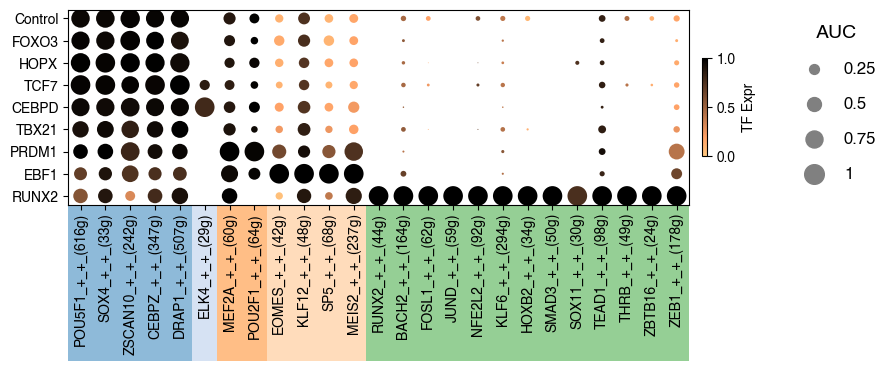

In [52]:
# One axis only
fig, ax_scatter = plt.subplots(figsize=(9, 3.75))

size_factor = 200

# Scatterplot
sns.scatterplot(
    data=merged_df_filt,
    x='Regulon',
    y='group',
    size='AUC',
    hue='Exp',
    palette='copper_r',
    ax=ax_scatter,
    sizes=(
        merged_df_filt['AUC'].min() * size_factor,
        merged_df_filt['AUC'].max() * size_factor
    ),
    legend=False
)

ax_scatter.set_xlim(-0.5, len(regulon_order) - 0.5)

# Bottom colour blocks drawn relative to scatter axis only
trans = ax_scatter.get_xaxis_transform()

for start, end, group_name in merged_blocks:
    x0 = start - 0.5
    width = end - start + 1
    color = group_color.get(group_name, 'lightgrey')

    rect = Rectangle(
        (x0, -0.8),      # x in data coords, y in axis coords
        width,
        0.8,
        transform=trans,
        facecolor=color,
        edgecolor='none',
        alpha=0.5,
        clip_on=False
    )
    ax_scatter.add_patch(rect)

# Size legend
size_values = [0.25, 0.5, 0.75, 1]
size_handles = [
    plt.scatter([], [], s=size * size_factor, color='gray', label=str(size))
    for size in size_values
]

ax_scatter.legend(
    handles=size_handles,
    title='AUC',
    labelspacing=1.2,
    loc='upper left',
    bbox_to_anchor=(1.15, 1.0),
    title_fontsize=14,
    fontsize=12,
    frameon=False
)

# Colorbar
norm = Normalize(vmin=merged_df_filt['Exp'].min(), vmax=merged_df_filt['Exp'].max())
sm = ScalarMappable(cmap='copper_r', norm=norm)
sm.set_array([])
colorbar = plt.colorbar(sm, ax=ax_scatter, fraction=0.05, pad=0.02, shrink=0.5)
colorbar.set_label('TF Expr')

ax_scatter.set_xlabel('')
ax_scatter.set_ylabel('')
ax_scatter.tick_params(axis='x', rotation=90, pad=2)

plt.subplots_adjust(bottom=0.55, right=0.82)

plt.tight_layout()

plt.savefig('GRN_activators_regulons_dotplot.pdf')

plt.show()
